# GAN discriminator as an OOD score

Can a discriminator trained against generated sensor windows detect unfamiliar real movement?

Read top-to-bottom: setup → equations → architecture → training → figures → LOTO → interpretation.
**Safe default:** saved-result exploration only; training is disabled.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'ml/sci_rob/vanilla/registry.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter within this repository.')
sys.path.insert(0, str(ROOT / 'notebooks/sci_rob/model_exploration'))
get_ipython().run_line_magic('matplotlib', 'inline')
from _exploration import *
import torch
from dataclasses import asdict
torch.set_num_threads(2)  # small architecture checks; training CLI runs separately
torch.manual_seed(0)
RUN_TRAINING = False
print('Repository:', ROOT)
print('Kernel:', sys.executable)

Repository: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton
Kernel: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python


In [2]:
KEY = 'gan'
RUN = ROOT / RUNS[KEY]
inventory(RUN)

**Artifact directory:** `ml/sci_rob/vanilla/runs/gan`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


## Data and evaluation contract

- Input: **16 channels × 200 samples**, one second at 200 Hz; stored window stride 10 samples.
- Original ID tasks: level ground (LG), ramp ascent (RA), ramp descent (RD).
  Original pseudo-OOD tasks: stair ascent (SA), stair descent (SD), standing (ST), transitions (TR).
- Participants: 12 train / 4 validation / 4 test. Task availability differs by participant.
  Input scaling is fitted on training data, never refitted on test data.
- Scoring does **not** predict a task label. High $\Psi$ means more anomalous.

$$\widetilde\Psi_t=\operatorname{median}(\Psi_{t-9},\ldots,\Psi_t),\qquad
\tau=Q_{0.995}(\widetilde\Psi_{\mathrm{train,ID}}),\qquad
\widehat o_t=\mathbf1[\widetilde\Psi_t>\tau].$$

Filtering restarts for each trial; early windows use the available history. The ten-score
filter corresponds to the repository's nominal 0.5 s smoothing setting, **not** ten raw samples.

$$\mathrm{recall}=\frac{TP}{TP+FN},\quad
\mathrm{specificity}=\frac{TN}{TN+FP},\quad J=\mathrm{recall}+\mathrm{specificity}-1.$$

AUROC measures ranking across thresholds; it is **not the fraction of OOD detected**.
OOD is the positive class. Tables below show J on −1 to 1, although source JSON stores 100J.
Scores and thresholds are not calibrated probabilities of being unsafe.

## Model and mathematics

A generator maps normal noise of shape 10 × 40 to a 16 × 200 window.
 ConvTranspose1d channels are 10 → 10 → 12 → 16, with strides (5,1,1), kernel 3,
 BatchNorm and LeakyReLU on hidden layers. The discriminator has two kernel-5 spectral-normalized
 convolutions (16 → 30 → 30), ReLU/dropout 0.2, global average pooling, and a scalar logit $s(x)$.

 $$D(x)=\operatorname{sigmoid}(s(x)),\qquad \Psi(x)=1-D(x).$$
 $$\mathcal L_D=-\mathbb E_x\log D(x)-\mathbb E_z\log(1-D(G(z))),\qquad
 \mathcal L_G=-\mathbb E_z\log D(G(z)).$$
 The code uses BCEWithLogitsLoss for stability. The discriminator learns **training-real
 versus generated**, not an explicitly supervised ID/OOD classifier. Its output is not an OOD probability.

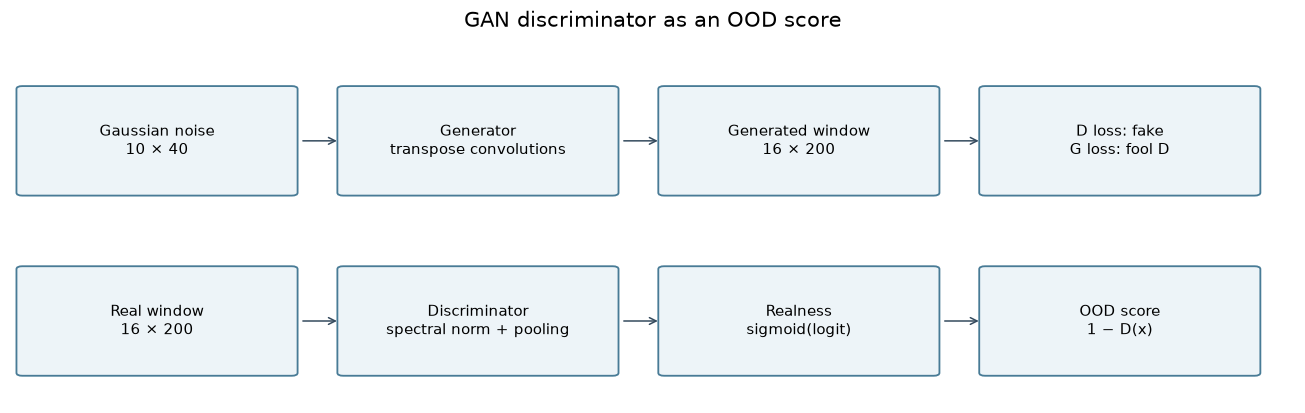

In [3]:
diagram([['Gaussian noise\n10 × 40', 'Generator\ntranspose convolutions', 'Generated window\n16 × 200', 'D loss: fake\nG loss: fool D'], ['Real window\n16 × 200', 'Discriminator\nspectral norm + pooling', 'Realness\nsigmoid(logit)', 'OOD score\n1 − D(x)']], 'GAN discriminator as an OOD score')

### Executable architecture check

This constructs **fresh random weights** and checks shapes only. The saved figures later come from trained runs; this dummy forward pass does not.

In [4]:
from models.gan import create_gan
model = create_gan()
example = torch.zeros(2, 16, 200)
output = model_shapes(model, example)

HipGan: 8,309 parameters
Input: (2, 16, 200)   Outputs: [(2,)]


,module,class,direct parameters
0,generator.net.0,ConvTranspose1d,310
1,generator.net.1,BatchNorm1d,20
2,generator.net.2,LeakyReLU,0
3,generator.net.3,ConvTranspose1d,372
4,generator.net.4,BatchNorm1d,24
5,generator.net.5,LeakyReLU,0
6,generator.net.6,ConvTranspose1d,592
7,discriminator.features.0.parametrizations.weig...,_SpectralNorm,0
8,discriminator.features.1,ReLU,0
9,discriminator.features.2,Dropout,0


## Training

Fixed 500 epochs, no early stopping. Adam β=(0.5,0.999); generator LR 0.0002, discriminator LR 0.00005; exponential LR decay 0.99. Five generator steps per discriminator step. Batch 256; every second stored training window (effective stride 20), but full evaluation windows. The internal participant holdout is monitored, not used to stop training.

In [5]:
from registry import get
config_class = get(KEY).config()
display(pd.Series(asdict(config_class()), name='current default').to_frame())

,current default
lr,0.0002
lr_d,0.00005
lr_decay,0.99
betas,"(0.5, 0.999)"
batch_size,256
max_epochs,500
g_steps_per_d,5
checkpoint_every,5
val_fraction,0.2
seed,0


### Saved training configuration and learning curves

Current defaults can differ from a past run. Below we read the report; missing reports remain explicitly missing. Loss scales from different objectives are not directly comparable.

,saved value
lr,0.0002
lr_d,0.00005
lr_decay,0.99
betas,"[0.5, 0.999]"
batch_size,256
max_epochs,500
g_steps_per_d,5
checkpoint_every,5
val_fraction,0.2
seed,0


,saved result
epochs_run,500
n_train_windows,79156
threshold,0.568925
psi_train_median,0.308411
psi_train_iqr,0.141509
internal early-stopping participants,"AB18, AB28"


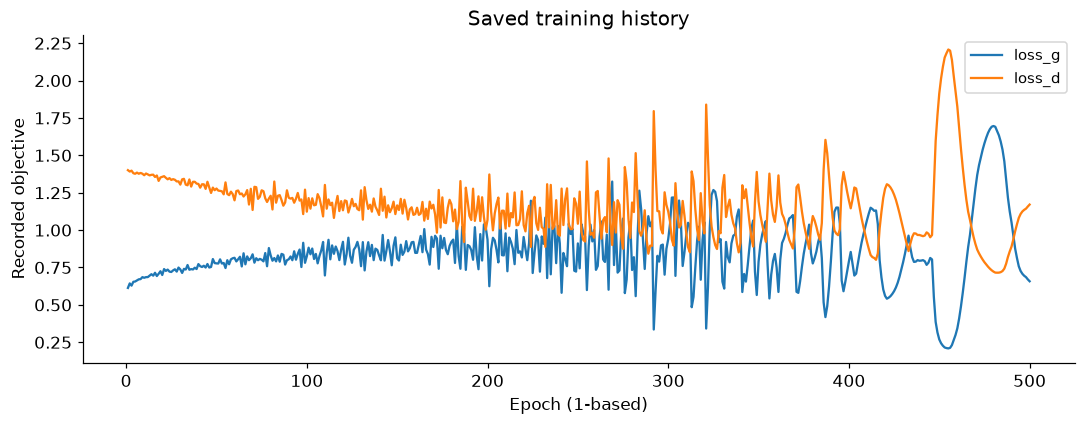

,epoch,loss_g,loss_d,lr_g,lr_d,seconds,d_real,d_fake,psi_median,psi_spread
495,495,0.707423,1.124466,0.000001,3.420003e-07,11.3,0.622787,0.502164,0.372261,0.080673
496,496,0.694386,1.135182,0.000001,3.385803e-07,11.3,0.623800,0.507368,0.370807,0.082279
497,497,0.685166,1.143114,0.000001,3.351945e-07,11.3,0.624820,0.510171,0.369117,0.083875
498,498,0.670125,1.157432,0.000001,3.318426e-07,11.3,0.625706,0.521400,0.367786,0.085477
499,499,0.657569,1.170342,0.000001,3.285242e-07,11.2,0.626343,0.533509,0.366841,0.087026


In [6]:
config_and_history(RUN)

### Optional: run the real training pipeline

This can take hours. The commands use this kernel’s Python and write to a **new** directory. Set `RUN_TRAINING=True` in the setup cell only when ready. Existing runs are protected. After completion, set `RUN = NEW_RUN` and rerun the result cells.

In [7]:
NEW_RUN = ROOT / 'notebooks/sci_rob/model_exploration/runs' / KEY
commands = training_commands(KEY, NEW_RUN)
run_commands(commands, NEW_RUN, enabled=RUN_TRAINING)

/Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/ml/sci_rob/vanilla/main.py all --model gan --out /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/sci_rob/model_exploration/runs/gan

Preview only. Set RUN_TRAINING=True explicitly to run.


## Saved test results

These values come directly from `eval_test.json`. An optimized test-ROC threshold, where reported, is diagnostic—not a validated operating point.

In [8]:
results_table(RUN)

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
primary,0.7273,10.8319,99.6853,0.1052,0.5689


,mode,kind,windows,flagged_%,median_psi
0,LG,ID,28668,0.6802,0.2986
1,RA,ID,18504,0.0000,0.2508
2,RD,ID,14784,0.0000,0.4209
3,SA,OOD,10273,0.0779,0.3042
4,SD,OOD,10155,9.2073,0.4851
5,TR,OOD,1994,46.7402,0.5325
6,ST,OOD,621,100.0000,0.7576


## Model behavior through figures

Images are embedded from the existing run, without rewriting it. Captions explain what each figure can and cannot establish.

**gan_generated.png** — Generated versus recorded windows; plausibility alone does not validate OOD detection.

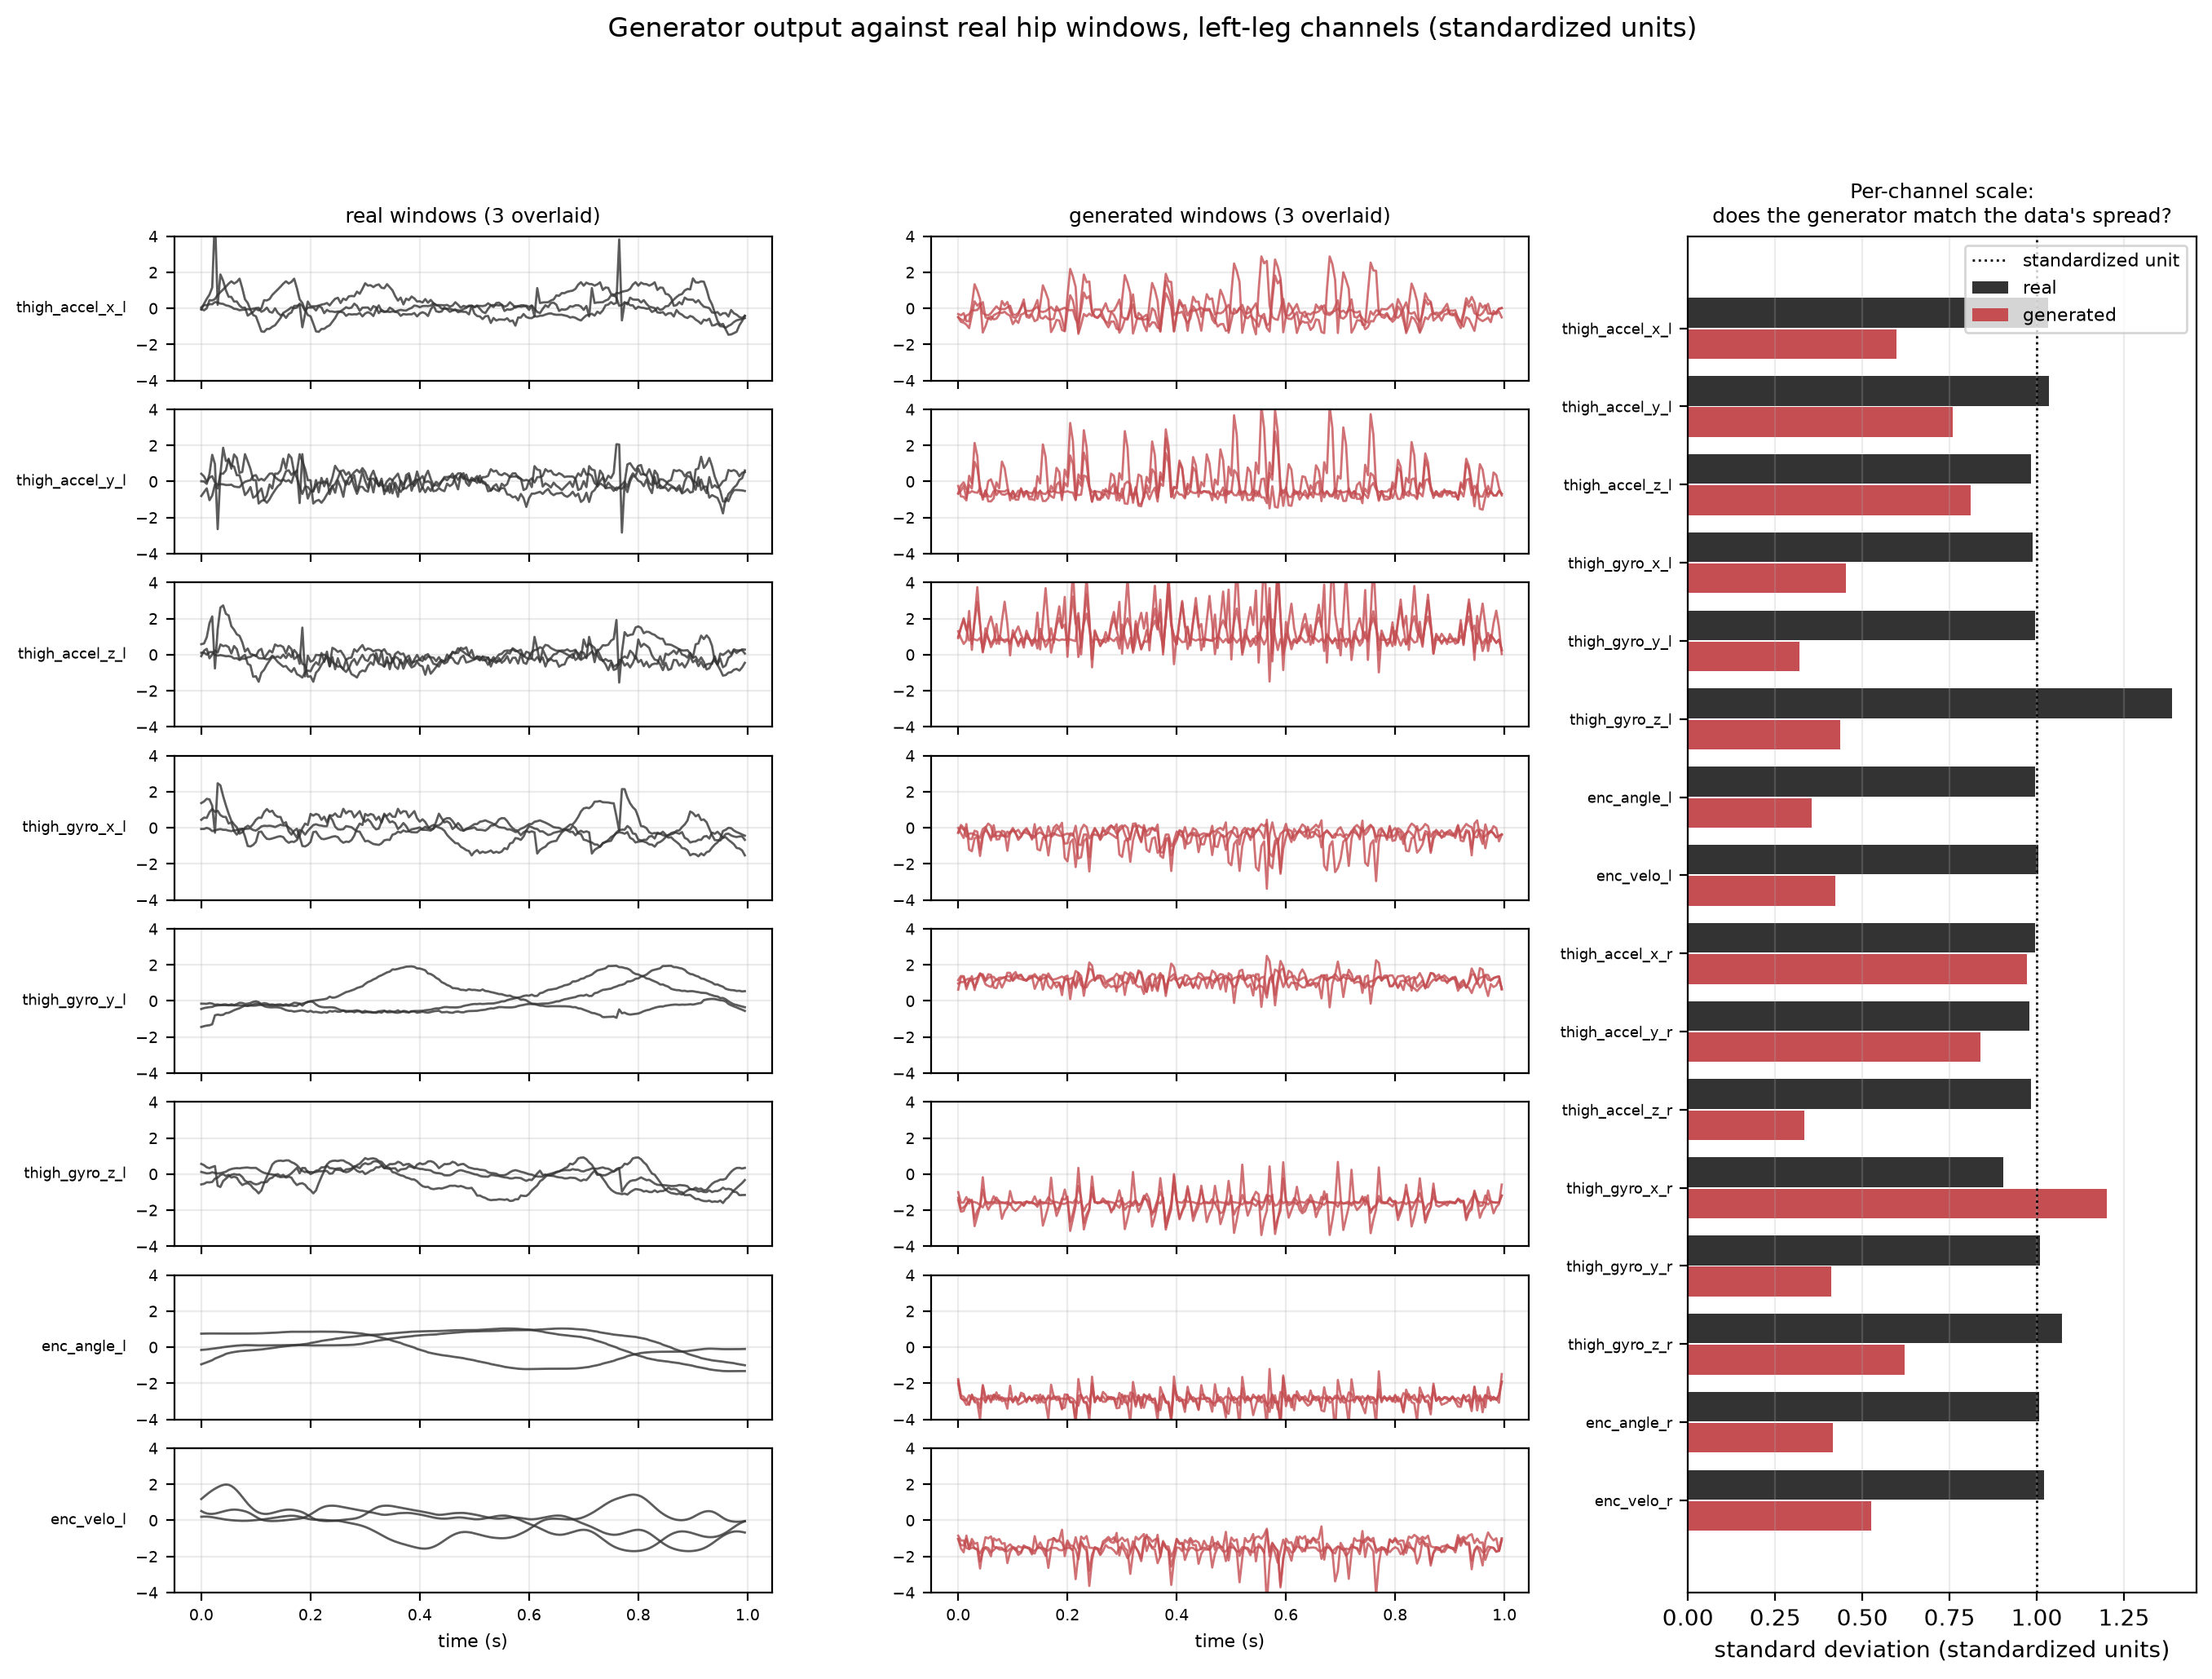

**gan_training_curve.png** — Both losses, discriminator outputs and score spread; check for saturation.

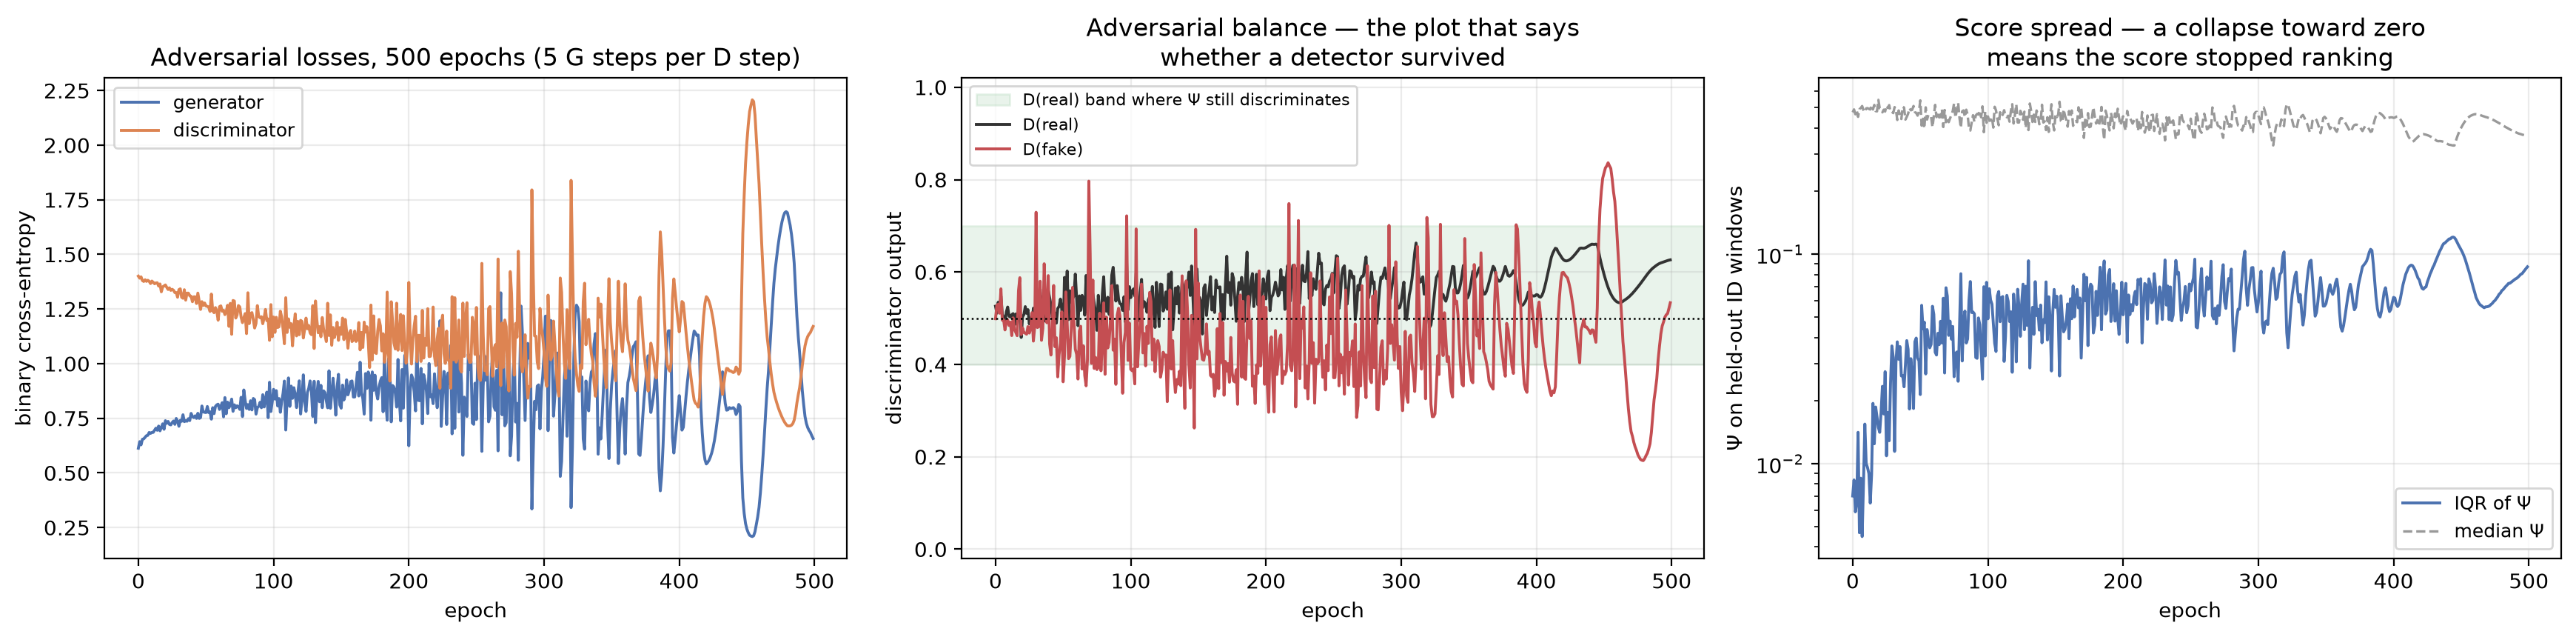

**gan_score_distribution.png** — Spread and saturation: a score can retain variation without separating tasks.

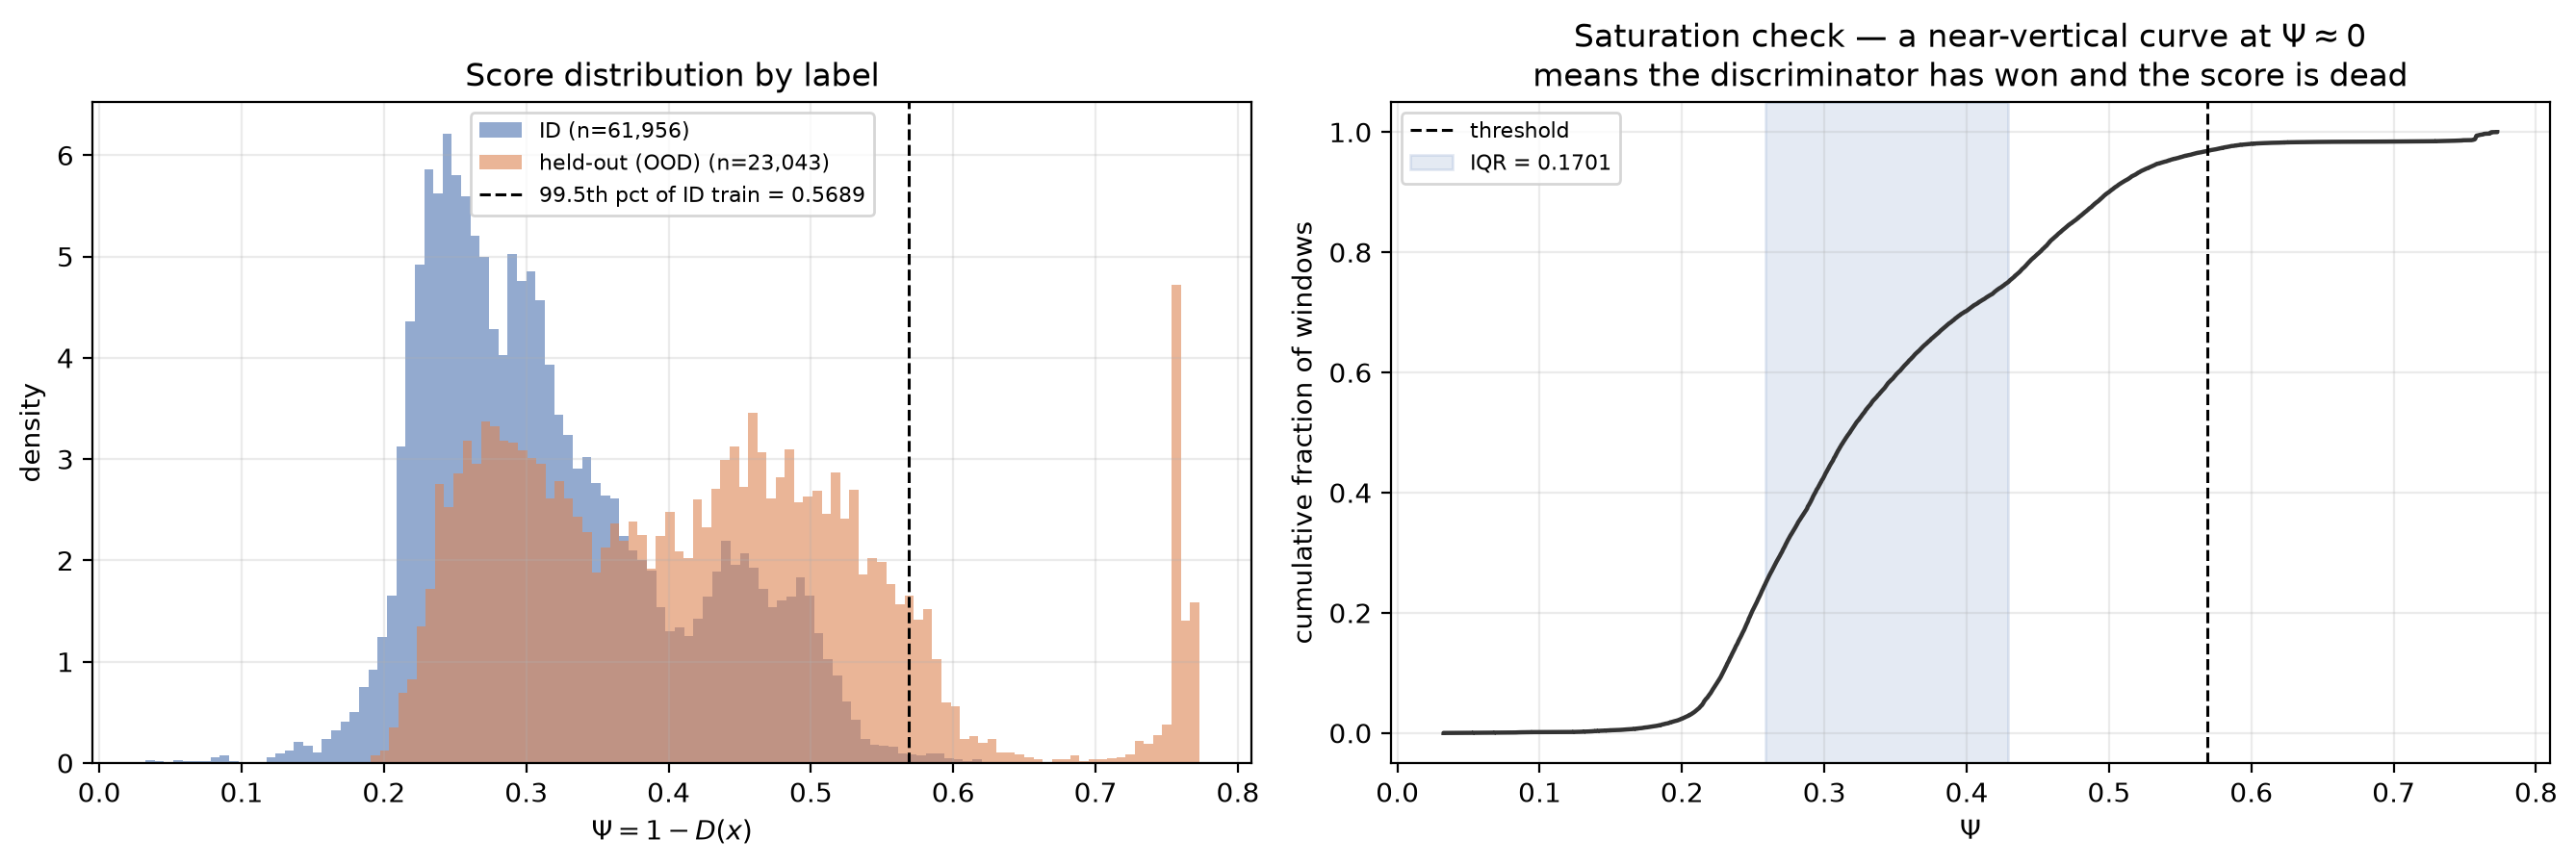

**gan_psi_by_task.png** — Task dependence of discriminator scores.

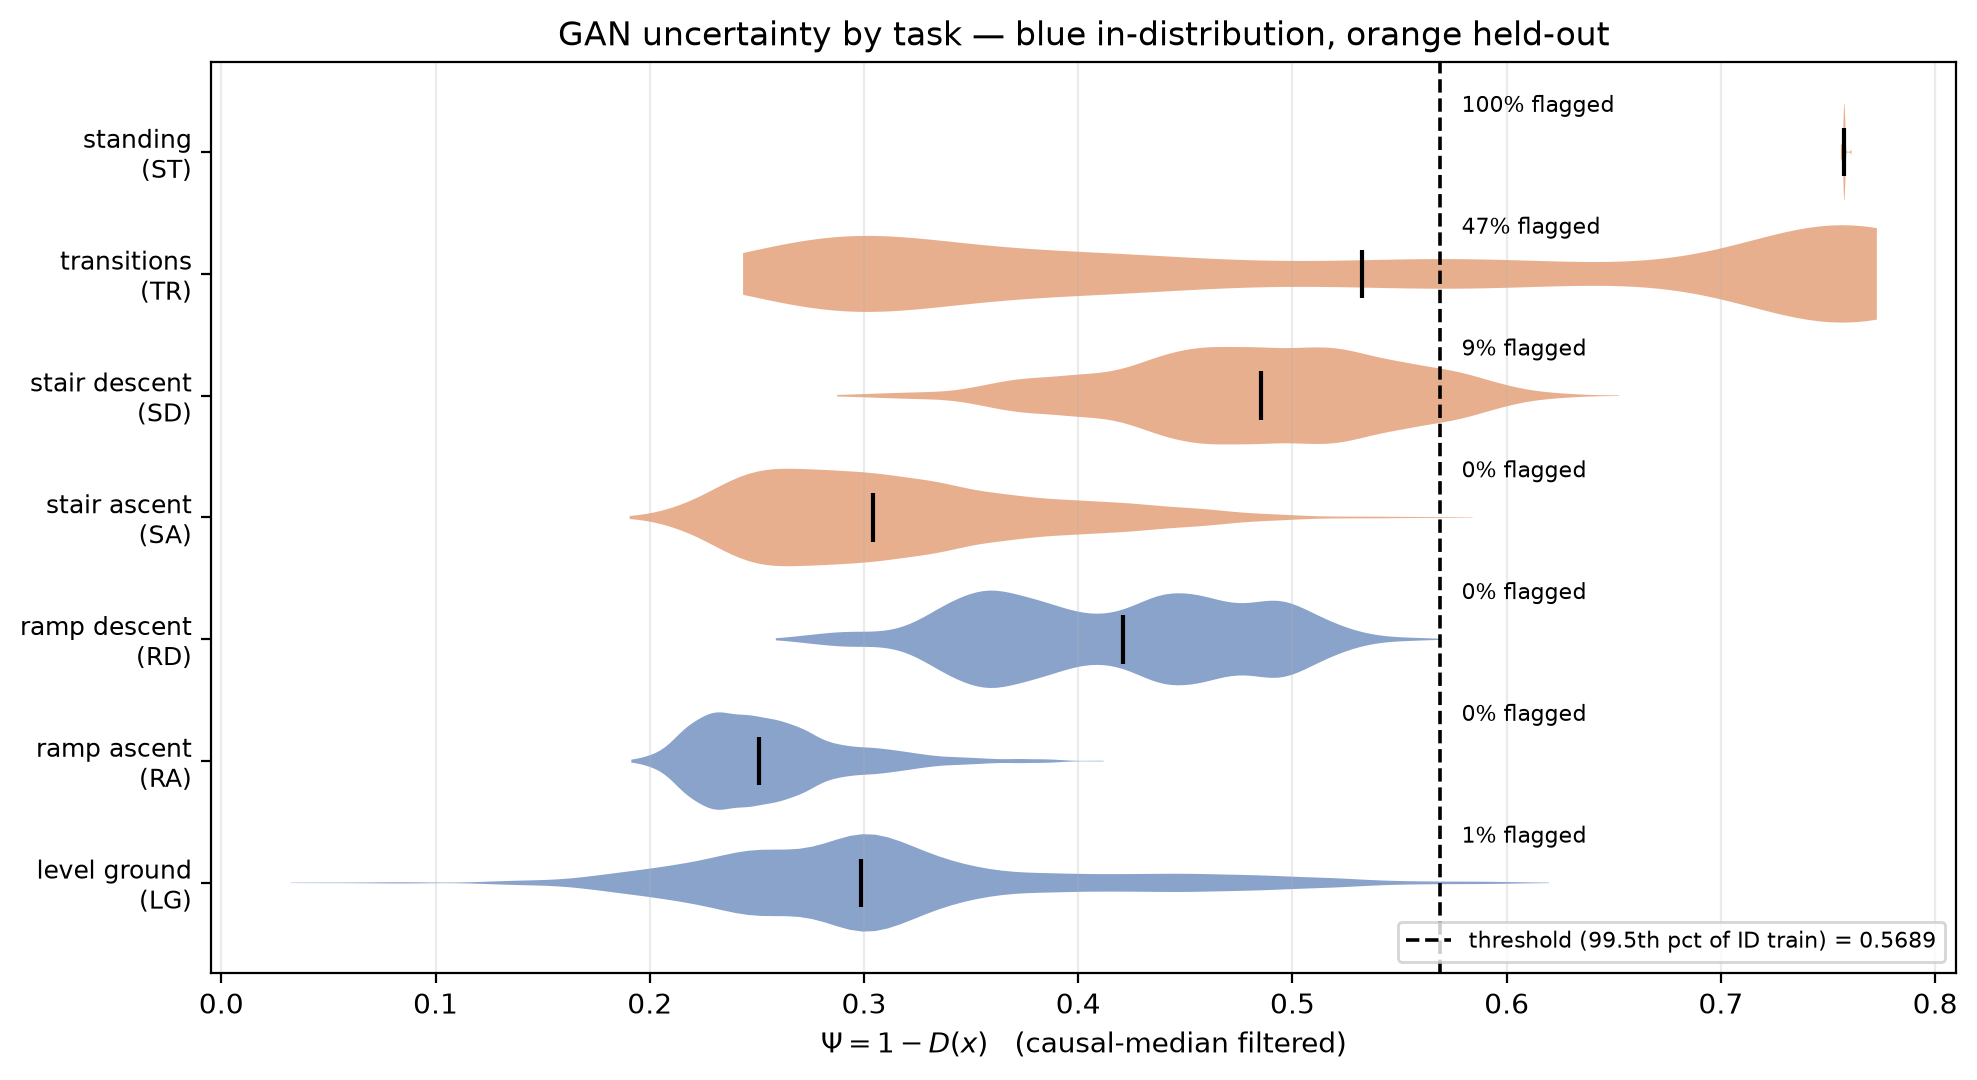

**gan_detection_by_task.png** — Thresholded detections and ID false alarms.

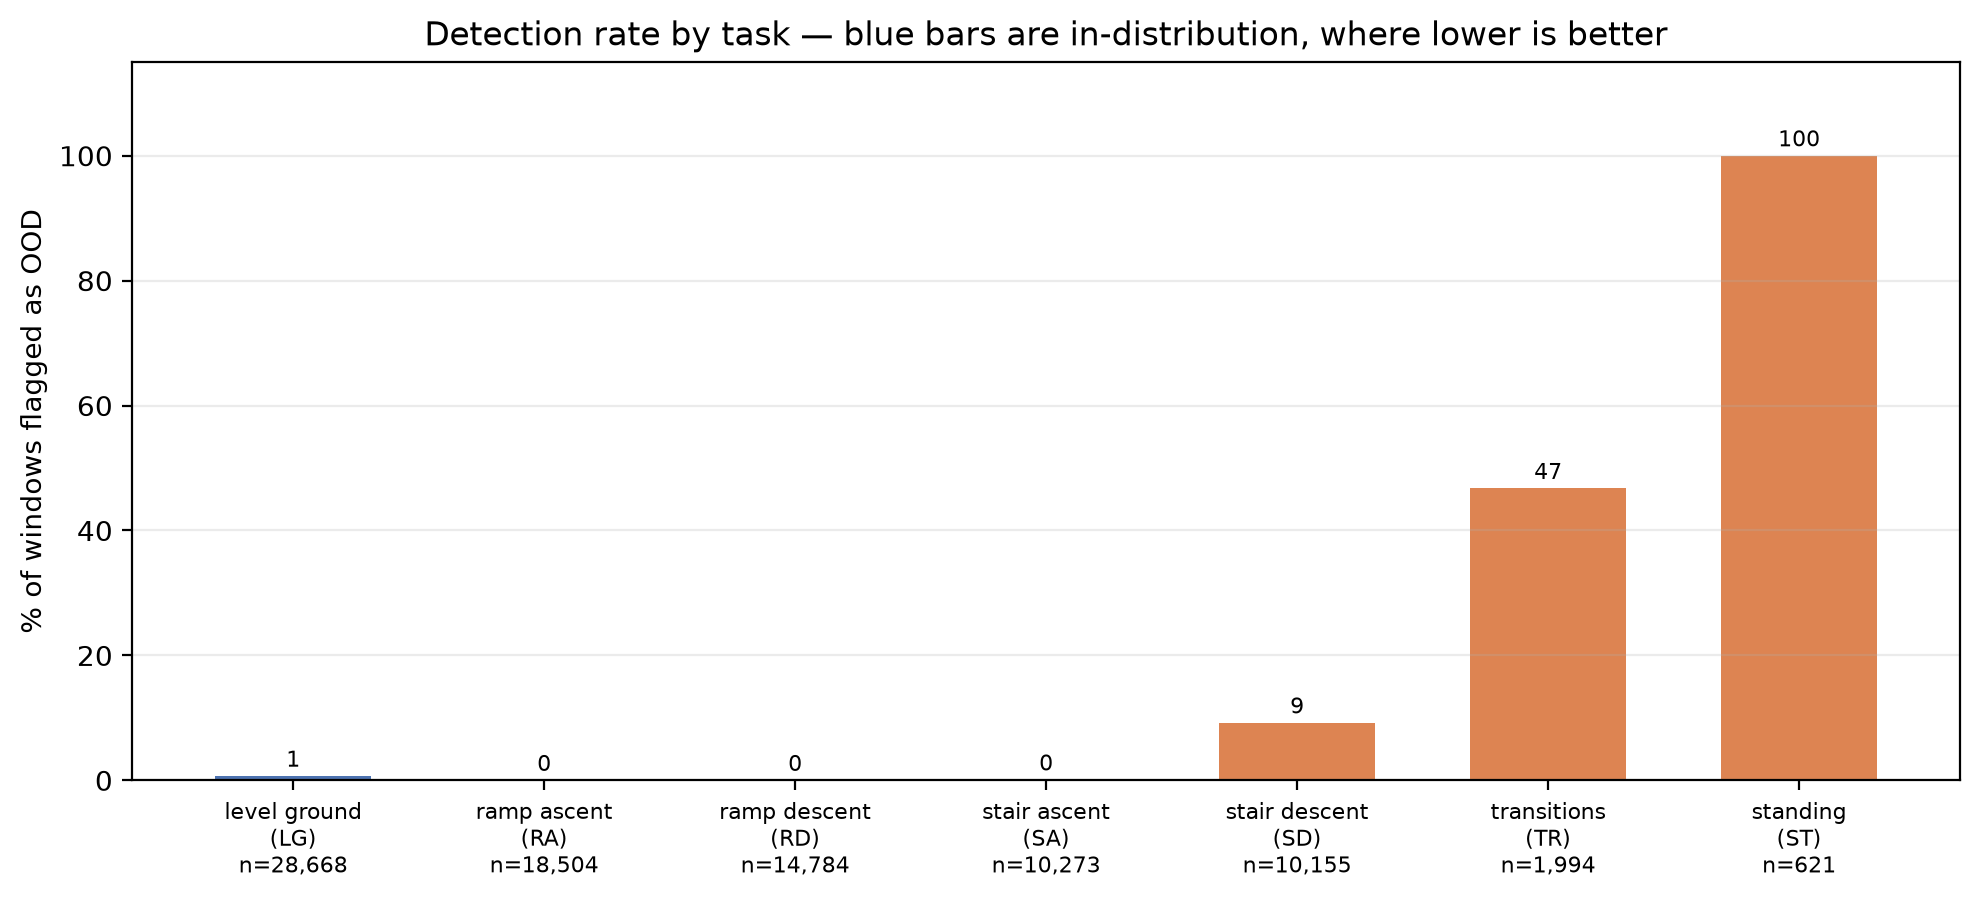

In [9]:
gallery(RUN, [('gan_generated.png', 'Generated versus recorded windows; plausibility alone does not validate OOD detection.'), ('gan_training_curve.png', 'Both losses, discriminator outputs and score spread; check for saturation.'), ('gan_score_distribution.png', 'Spread and saturation: a score can retain variation without separating tasks.'), ('gan_psi_by_task.png', 'Task dependence of discriminator scores.'), ('gan_detection_by_task.png', 'Thresholded detections and ID false alarms.')])

## Leave-one-task-out (LOTO) stress test

SA: stair ascent; ST: standing; TR: transitions. Each run excludes the named task from **all training participants**, trains on the other six, and tests on held-out participants. This differs from LOSO epoch selection.

Standing test data come from one trial of one participant: 621 overlapping windows, or 600 for the gait-phase subset. Gait-phase LOTO uses fewer labelled windows overall. Raw window counts are not independent repetitions; cross-run changes do not isolate a causal training effect.

,held out,score,AUROC,recall (%),ID false alarms (%),J,OOD windows
0,SA,primary,0.5336,0.0584,1.3008,-0.0124,10273
1,ST,primary,0.9824,0.0000,1.4399,-0.0144,621
2,TR,primary,0.7772,37.0110,0.7481,0.3626,1994


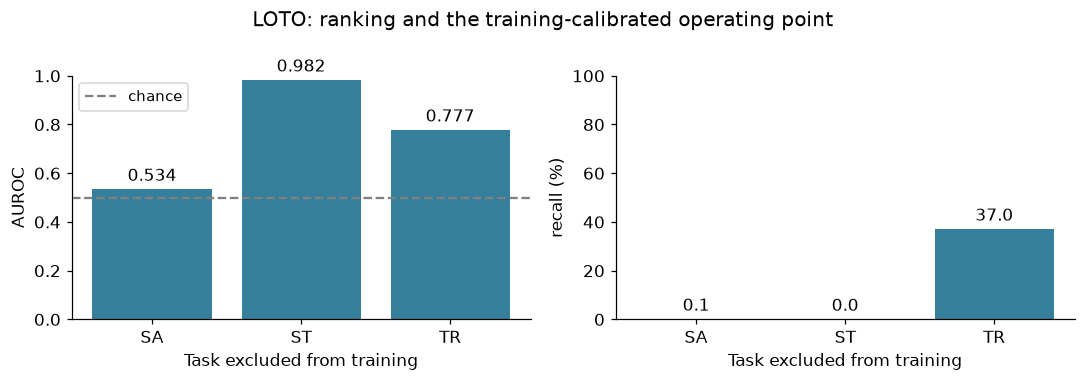

In [10]:
loto_results(KEY)

## LOTO score spread and threshold what-if

Each figure uses one separately trained holdout run: **only the named held-out task is
orange (OOD)**; the other six are blue (ID). The black dashed line is that run's saved
training threshold. Black bars span the middle 50% (IQR), with a tick at the median.
Density shapes use at most 1,500 quantile-spaced points per task; all medians, IQRs and
flag rates use **every saved test window**. Non-GAN scores use log10 axes when positive.
The plotted scores already include the original per-trial smoothing; they are not filtered again.

$$\operatorname{recall}(\tau)=\frac{\sum_{i:y_i=1}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm OOD}},
\qquad \operatorname{FPR}(\tau)=\frac{\sum_{i:y_i=0}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm ID}}.$$

**Try a threshold:** replace a `None` in `LOTO_THRESHOLDS` with a numeric score threshold
(in original units, **not log10**), then rerun this cell. A purple line and exact per-task
flag rates show the what-if; `None` uses the saved threshold. The right-hand staircase
and table show recall **and ID false alarms**, not AUROC. Changing the threshold does
not change AUROC, retrain anything, or overwrite saved results.

These are **exploratory test-set what-ifs**, not validated new operating points. Choose a
final threshold using validation data, not whichever test threshold looks best. Rates
are window-weighted; overlapping windows (especially the single standing trial) are
not independent repetitions. Missing runs remain explicitly unavailable.

### Held out: SA — stair ascent

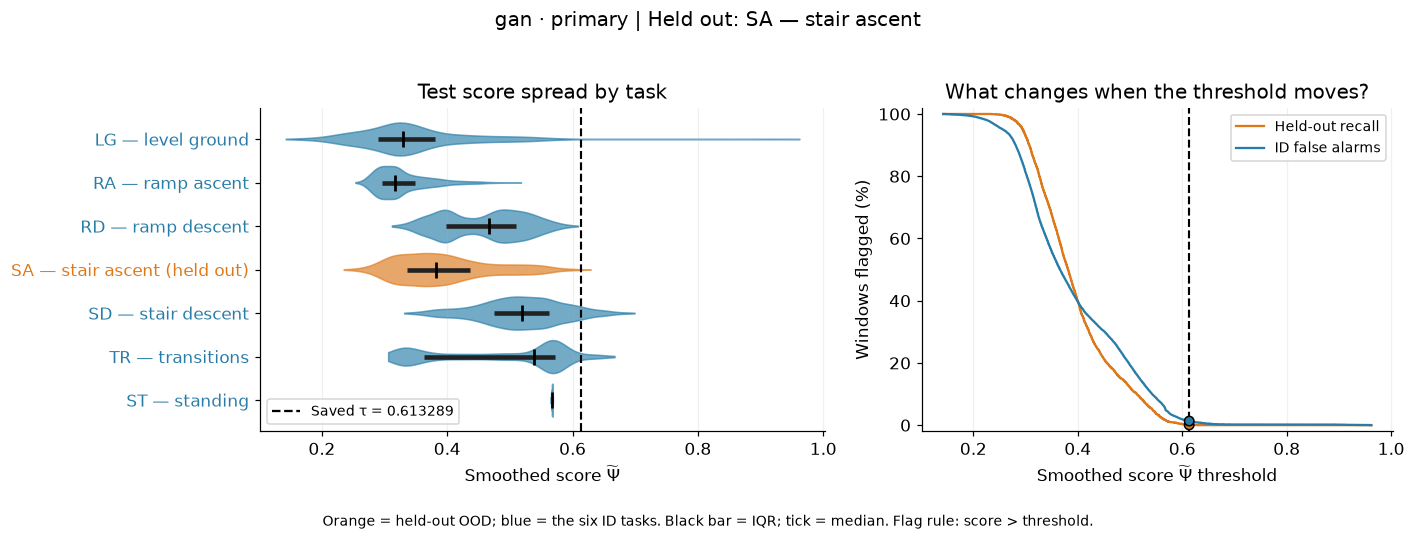

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.30664447,90.20,77.93
1,,0.4599667,19.13,28.39
2,,0.55196005,3.46,8.32
3,,0.58262449,0.89,3.08
4,,0.60715605,0.13,1.56
5,saved,0.61328894,0.06,1.30
6,,0.61942183,0.06,1.11
7,,0.64395339,0.00,0.56
8,,0.67461783,0.00,0.25
9,,0.76661117,0.00,0.17


**Per-task flags at τ = 0.61328894** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,0.46
1,RA,ID,18504,0.00
2,RD,ID,14784,0.00
3,SA,held-out OOD,10273,0.06
4,SD,ID,10155,7.37
5,TR,ID,1994,4.61
6,ST,ID,621,0.00


### Held out: ST — standing

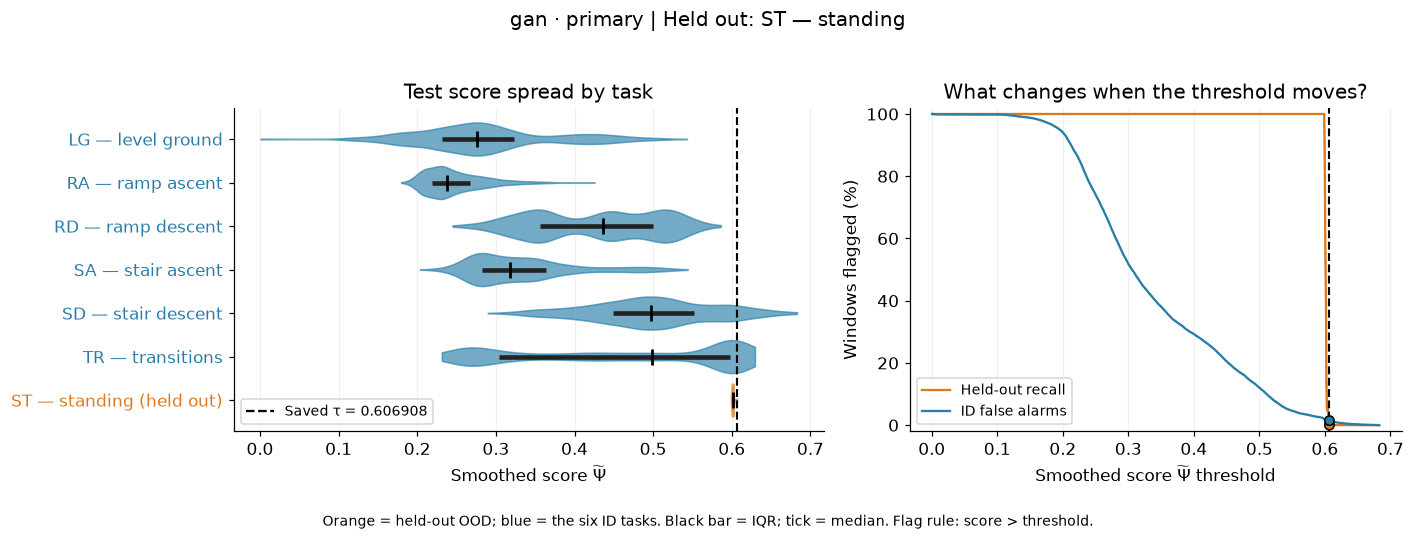

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.30345404,100.00,50.69
1,,0.45518106,100.00,19.52
2,,0.54621727,100.00,4.89
3,,0.57656268,100.00,3.18
4,,0.600839,52.82,1.78
5,saved,0.60690808,0.00,1.44
6,,0.61297716,0.00,1.03
7,,0.63725349,0.00,0.41
8,,0.66759889,0.00,0.09
9,,0.7586351,0.00,0.00


**Per-task flags at τ = 0.60690808** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,0.00
1,RA,ID,18504,0.00
2,RD,ID,14784,0.00
3,SA,ID,10273,0.00
4,SD,ID,10155,9.04
5,TR,ID,1994,14.89
6,ST,held-out OOD,621,0.00


### Held out: TR — transitions

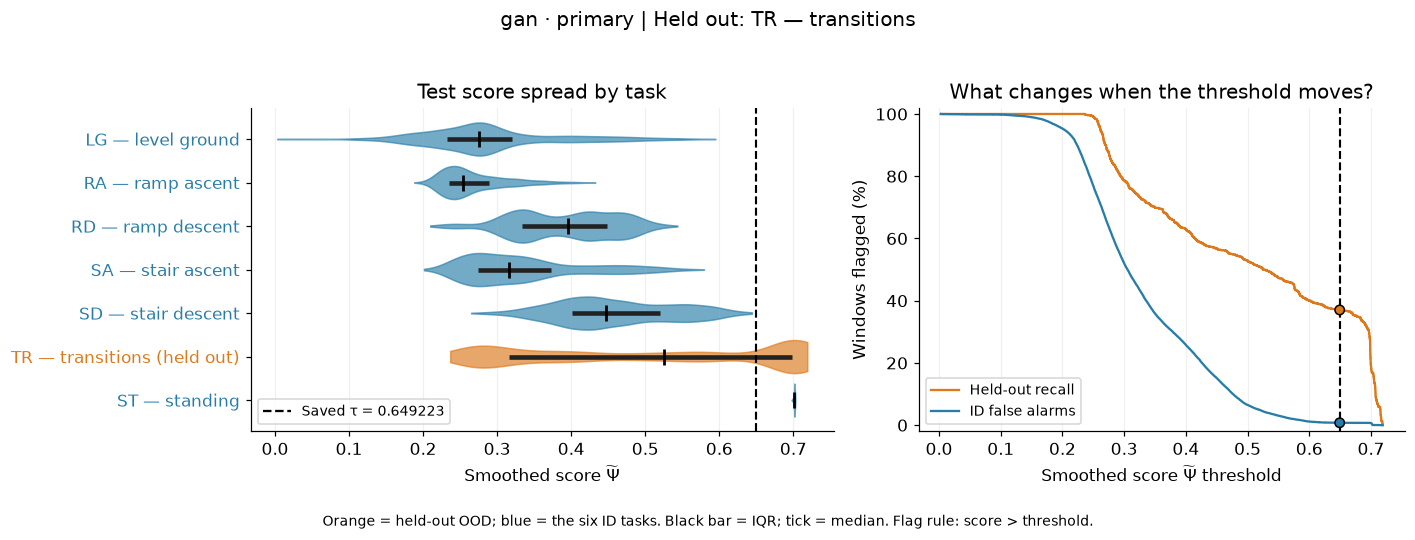

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.32461157,73.52,43.59
1,,0.48691736,54.26,8.22
2,,0.58430083,42.18,1.66
3,,0.61676199,38.87,0.90
4,,0.64273092,37.26,0.76
5,saved,0.64922315,37.01,0.75
6,,0.65571538,36.81,0.75
7,,0.68168431,34.65,0.75
8,,0.71414546,5.67,0.00
9,,0.81152894,0.00,0.00


**Per-task flags at τ = 0.64922315** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,0.00
1,RA,ID,18504,0.00
2,RD,ID,14784,0.00
3,SA,ID,10273,0.00
4,SD,ID,10155,0.00
5,TR,held-out OOD,1994,37.01
6,ST,ID,621,100.00


In [11]:
from _loto_exploration import loto_score_explorer, threshold_rates
LOTO_THRESHOLDS = {'SA': None, 'ST': None, 'TR': None}
LOTO_SCORE = 'primary'
loto_bundles = loto_score_explorer(KEY, score=LOTO_SCORE, thresholds=LOTO_THRESHOLDS)
# Exact custom query, e.g.: threshold_rates(loto_bundles['ST'], [0.59, 0.60])

## Takeaway and next checks

Inspect D(real), D(fake), and score spread together. In standing LOTO, excellent AUROC coexists with zero recall at the inherited training threshold. A healthy GAN loss is not evidence of a useful detector.

Keep score/threshold selection on validation data. Report both ranking and recall at a declared false-alarm budget, repeat seeds, and quantify participant/trial-level variation before making robustness claims.

In [12]:
source_links(['ml/common/models/gan.py', 'ml/sci_rob/vanilla/training/gan.py', 'ml/sci_rob/vanilla/evaluation/gan.py'])

Implementation sources: [gan.py](../../../ml/common/models/gan.py), [gan.py](../../../ml/sci_rob/vanilla/training/gan.py), [gan.py](../../../ml/sci_rob/vanilla/evaluation/gan.py)